# Analyse Big Data des accidents de la route avec PySpark

**Cours :** Fondements et Application de Big Data (16/10/2026)
**Étude de cas :** Road Crash

## Consigne

| # | À faire |
|---|---------|
| 1 | Refaire l'étude « Big Data Analysis of Road Crash Data using PySpark with PySpark Tutorial » |
| 2 | Rendu : un notebook avec le problème, les explications, le code, les tests, les comparaisons et la conclusion |
| 3 | L'ajouter au dépôt GitHub du cours |

**Sources :**
- l'article de Rakesh Nain sur Medium :
  [Big Data Analysis of Road Crash Data using PySpark](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588) ;
- son dépôt GitHub, qui contient le notebook de l'article et les données :
  [RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial).

On suit l'article partie par partie, dans le même ordre. À chaque étape, on compare nos résultats aux siens.

## Le problème

L'Australie-Méridionale (*South Australia*, capitale Adélaïde) publie la liste de tous les accidents de la
route enregistrés par la police. On prend les années 2012 à 2019 : environ **128 000 accidents** et
**273 000 véhicules ou piétons** impliqués. On veut répondre à des questions simples :

- **Qui** est impliqué ? (âge et sexe des conducteurs, âge des véhicules)
- **Où et comment** ? (quartiers, types d'accident, accidents les plus graves)
- **L'alcool et la drogue** rendent-ils les accidents plus graves ?

C'est aussi un exercice sur l'outil. Spark propose **trois façons** d'écrire le même calcul : les **RDD**,
les **DataFrames** et **SparkSQL**. Donnent-elles le même résultat ? Laquelle est la plus simple et la plus
rapide ?

## Plan

1. Environnement et données
2. Démarrer Spark
3. Analyse avec les RDD
4. Analyse avec les DataFrames
5. Alcool, drogue et gravité des accidents
6. Une même requête écrite trois fois : RDD, DataFrame, SparkSQL
7. Tests : vérification par un autre outil (pandas)
8. Comparaison des temps
9. Conclusion

## 1. Environnement et données

PySpark s'installe avec `pip`. Le paquet contient Spark lui-même, il n'y a pas de cluster à monter. Il faut
seulement Java (8, 11 ou 17 pour Spark 3.5).

```bash
pip install "pyspark>=3.5,<3.6" jupyter pandas matplotlib
```

Sous Windows, on indique à Spark quel Python utiliser pour ses processus (`PYSPARK_PYTHON`), sinon il
cherche une commande `python3` qui n'existe pas toujours.

In [1]:
import os, sys, platform, subprocess, time, csv, re, urllib.request
from operator import add
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import pyspark
from pyspark import SparkConf
from pyspark.rdd import RDD
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.functions import udf
from pyspark.sql.types import FloatType

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

java = subprocess.run("java -version", shell=True, capture_output=True, text=True)
print("Python     :", sys.version.split()[0])
print("Système    :", platform.platform(), "-", os.cpu_count(), "cœurs logiques")
print("PySpark    :", pyspark.__version__)
print("Java       :", (java.stderr or java.stdout).splitlines()[0])
print("pandas     :", pd.__version__)

Python     : 3.11.9
Système    : Windows-10-10.0.26300-SP0 - 12 cœurs logiques
PySpark    : 3.5.9
Java       : java version "1.8.0_471"
pandas     : 2.3.0


### Les tests

Tout au long du notebook, on vérifie nos résultats avec une petite fonction `verifier` : elle compare une
valeur obtenue à la valeur attendue (celle de l'article, ou celle d'un autre calcul) et garde une trace.
Le bilan de tous les tests est affiché à la fin (partie 7).

In [2]:
TESTS = []

def verifier(nom, obtenu, attendu):
    # Compare `obtenu` à `attendu`, affiche OK ou ÉCHEC et garde le résultat pour le bilan final.
    ok = obtenu == attendu
    TESTS.append({"test": nom, "résultat": "OK" if ok else "ÉCHEC",
                  "obtenu": str(obtenu)[:60], "attendu": str(attendu)[:60]})
    print(("OK    " if ok else "ÉCHEC ") + nom + ("" if ok else f" : obtenu {obtenu!r}, attendu {attendu!r}"))
    return ok

### Les données

Les données viennent du ministère des transports d'Australie-Méridionale (DPTI), publiées sur
[data.sa.gov.au](https://data.sa.gov.au). L'auteur les a copiées dans son dépôt GitHub : on les télécharge
de là (environ 80 Mo, une seule fois) dans `data/road_crash/`. Le dossier `data/` n'est pas versionné.

Il y a deux tables, avec un fichier CSV par année :

| Table | Une ligne = | Colonnes utiles |
|---|---|---|
| **Crash** (`crash_data/`) | un **accident** | `REPORT_ID`, `Suburb` (quartier), `Total Cas` (nombre de victimes), `Total Fats` (nombre de morts), `Year`, `Month`, `Day`, `Time`, `Crash Type`, `CSEF Severity` (gravité), `DUI Involved` (alcool), `Drugs Involved` (drogue) |
| **Units** (`units_data/`) | une **unité** impliquée : véhicule, vélo ou piéton | `REPORT_ID`, `No Of Cas` (victimes dans cette unité), `Veh Reg State` (État d'immatriculation), `Unit Type`, `Veh Year` (année du véhicule), `Sex`, `Age`, `Licence Type` (type de permis) |

Les deux tables sont reliées par `REPORT_ID`, le numéro de l'accident : **un accident a une ou plusieurs
unités**. Le jour exact n'est pas publié (donnée sensible) : `Day` est le **jour de la semaine**. Une date
s'écrit donc comme le demande l'auteur : `2017-January-Sunday`.

In [3]:
DEPOT = ("https://raw.githubusercontent.com/RakeshNain/"
         "Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/main")
DATA_DIR = Path("data/road_crash")
ANNEES = range(2012, 2020)
TABLES = {"crash_data": "Crash", "units_data": "Units"}

for dossier, suffixe in TABLES.items():
    (DATA_DIR / dossier).mkdir(parents=True, exist_ok=True)
    for annee in ANNEES:
        chemin = DATA_DIR / dossier / f"{annee}_DATA_SA_{suffixe}.csv"
        if not chemin.exists():
            urllib.request.urlretrieve(f"{DEPOT}/{dossier}/{chemin.name}", chemin)

def compter_lignes(chemin):
    with open(chemin, "rb") as f:
        return sum(1 for _ in f)

lignes = []
for dossier, suffixe in TABLES.items():
    for annee in ANNEES:
        chemin = DATA_DIR / dossier / f"{annee}_DATA_SA_{suffixe}.csv"
        lignes.append({"table": dossier, "année": annee, "lignes (avec l'en-tête)": compter_lignes(chemin),
                       "taille (Mo)": round(chemin.stat().st_size / 1e6, 1)})
inventaire = pd.DataFrame(lignes)
print(f"{len(inventaire)} fichiers, {inventaire['taille (Mo)'].sum():.0f} Mo")
inventaire.pivot(index="année", columns="table", values="lignes (avec l'en-tête)")

16 fichiers, 80 Mo


table,crash_data,units_data
année,,
2012,22830,48321
2013,16676,35866
2014,16163,34553
2015,15432,33085
2016,16776,35862
2017,13238,28164
2018,13600,29034
2019,12965,27714


Les deux premières lignes d'un fichier d'accidents. La première est l'en-tête (le nom des colonnes). On
remarque que certains champs entre guillemets contiennent eux-mêmes une virgule, comme
`"CC OF NORWOOD,PAYNEHAM & ST PETERS"` : on y reviendra en partie 3.4, c'est un piège.

In [4]:
with open(DATA_DIR / "crash_data" / "2012_DATA_SA_Crash.csv", encoding="utf-8") as f:
    print(f.readline()[:300])
    print(f.readline()[:300])

"REPORT_ID","Stats Area","Suburb","Postcode","LGA Name","Total Units","Total Cas","Total Fats","Total SI","Total MI","Year","Month","Day","Time","Area Speed","Position Type","Horizontal Align","Vertical Align","Other Feat","Road Surface","Moisture Cond","Weather Cond","DayNight","Crash Type","Unit R
"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Divided","Straight road","Level","Driveway or Entrance","Sealed","Dry","Not Raining","Daylight","Right Angle","02","Driver Rider","1: PDO","No Control","


## 2. Démarrer Spark

### Calcul parallèle ou distribué ?

L'auteur insiste sur une nuance :

- **calcul parallèle** : le travail est réparti entre les **cœurs d'une seule machine** ;
- **calcul distribué** : le travail est réparti entre **plusieurs machines** (un cluster).

Spark fait les deux avec le même code. Seule la configuration change. Ici on n'a qu'un ordinateur, on fait
donc du calcul parallèle : `local[*]` veut dire « en local, avec autant de fils d'exécution que de cœurs ».
`local[4]` en utiliserait 4.

Un réglage est propre à Windows. Spark (écrit en Java) confie nos `lambda` à des processus Python et
échange les données avec eux par une connexion réseau locale. Sous Linux, cette connexion n'a pas de délai
d'attente ; sous Windows, PySpark 3.5 lui en laisse un de **15 secondes**. Quand Java met plus
longtemps à lire la réponse, par exemple pendant une grosse jointure, le processus Python abandonne et le
calcul plante (`Connection reset by peer`). On porte donc ce délai à une heure
(`spark.python.authenticate.socketTimeout`).

### Configuration et session

- `SparkConf` regroupe les réglages (où tourner, nom de l'application...).
- `SparkSession` est le point d'entrée des DataFrames et de SparkSQL.
- `SparkContext` (`sc`) est le point d'entrée des RDD. Il est contenu dans la session.

C'est à la création de la session que Spark démarre sa machine virtuelle Java : on mesure ce temps.

In [5]:
master = "local[*]"                                  # tous les cœurs de la machine
app_name = "Big data Analysis of Road Crash Data"

spark_conf = (SparkConf().setMaster(master).setAppName(app_name)
              .set("spark.driver.memory", "2g")
              .set("spark.ui.showConsoleProgress", "false")
              .set("spark.python.authenticate.socketTimeout", "3600s"))   # Windows : délai Java <-> Python

t0 = time.perf_counter()
spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")
t_session = time.perf_counter() - t0

print(f"Session Spark prête en {t_session:.1f} s")
print("Spark        :", spark.version)
print("Master       :", sc.master)
print("Parallélisme :", sc.defaultParallelism, "tâches en même temps")

Session Spark prête en 21.6 s
Spark        : 3.5.9
Master       : local[*]
Parallélisme : 12 tâches en même temps


## 3. Analyse avec les RDD

### 3.1 Qu'est-ce qu'un RDD ?

Un **RDD** (*Resilient Distributed Dataset*) est une **liste géante découpée en morceaux**, les
**partitions**. Chaque partition peut être traitée par un cœur différent, en même temps que les autres.

- On ne modifie jamais un RDD : chaque opération en crée un nouveau.
- Il y a deux sortes d'opérations. Les **transformations** (`map`, `filter`...) décrivent un calcul mais
  ne font rien tout de suite. Les **actions** (`collect`, `count`, `take`...) lancent vraiment le calcul.
  On dit que Spark est **paresseux** : il attend la dernière minute pour tout faire d'un coup.
- *Resilient* (résistant) : si une partition est perdue, Spark sait la recalculer.

On crée un RDD de deux façons :
- `parallelize()` : à partir d'une liste Python ;
- `textFile()` : à partir de fichiers texte, **une ligne = un élément**.

Exemple avec `parallelize()` sur les nombres de 0 à 9. `glom()` regroupe chaque partition en une liste,
pour voir le découpage.

In [6]:
data_list = list(range(10))

rdd = sc.parallelize(data_list)                  # par défaut : autant de partitions que de cœurs
print("Partitions par défaut :", rdd.getNumPartitions())

rdd = sc.parallelize(data_list, 5)               # second argument : nombre de partitions choisi
print("Partitions choisies   :", rdd.getNumPartitions())
print("Contenu de chaque partition :", rdd.glom().collect())
print("collect()             :", rdd.collect())

Partitions par défaut : 12
Partitions choisies   : 5


Contenu de chaque partition : [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]
collect()             : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


L'auteur obtenait 8 partitions par défaut : sa machine avait 8 cœurs. On en a autant que de cœurs logiques
ici. Avec 5 partitions, Spark coupe la liste en 5 morceaux de 2 nombres.

### 3.2 Charger les fichiers

On charge les 8 années d'un coup dans un seul RDD. L'article écrit `textFile('./units_data/*.csv')`.
Sous Windows, ce motif avec `*` fait planter Spark s'il manque l'utilitaire Hadoop `winutils.exe`
(erreur `UnsatisfiedLinkError ... NativeIO`). On passe donc la **liste des fichiers**, séparés par des
virgules : `textFile()` l'accepte et le résultat est le même.

In [7]:
def fichiers(dossier):
    # Liste des 8 fichiers CSV d'une table (équivalent du motif dossier/*.csv).
    return [p.as_posix() for p in sorted((DATA_DIR / dossier).glob("*.csv"))]

units_rdd = sc.textFile(",".join(fichiers("units_data")))
crash_rdd = sc.textFile(",".join(fichiers("crash_data")))
print(units_rdd.take(2))

['"REPORT_ID","Unit No","No Of Cas","Veh Reg State","Unit Type","Veh Year","Direction Of Travel","Sex","Age","Lic State","Licence Class","Licence Type","Towing","Unit Movement","Number Occupants","Postcode","Rollover","Fire"', '"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,']


La première ligne est l'en-tête. On la récupère avec `first()`, puis on garde toutes les lignes **qui ne
lui sont pas égales**. Comme chacun des 8 fichiers commence par le même en-tête, ce filtre enlève les 8
en-têtes d'un coup.

In [8]:
units_header = units_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header)
print("Nombre d'unités    :", units_rdd.count())

crash_header = crash_rdd.first()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header)
print("Nombre d'accidents :", crash_rdd.count())
print()
for ligne in crash_rdd.take(3):
    print(ligne[:150], "...")

Nombre d'unités    : 272591


Nombre d'accidents : 127672



"2012-1-21/08/2019","2 Metropolitan","STEPNEY","5069","CC OF NORWOOD,PAYNEHAM & ST PETERS",2,0,0,0,0,2012,"January","Sunday","04:30 pm","060","Not Div ...
"2012-2-21/08/2019","2 Metropolitan","PARKSIDE","5063","CITY OF UNLEY",2,0,0,0,0,2012,"January","Sunday","09:10 am","040","Not Divided","Straight road ...
"2012-3-21/08/2019","2 Metropolitan","SELLICKS BEACH","5174","CITY OF ONKAPARINGA",3,0,0,0,0,2012,"January","Wednesday","11:30 am","100","Not Divided" ...


**Test :** l'article trouve 272 591 unités et 127 672 accidents. On vérifie aussi qu'on a bien enlevé les
8 en-têtes : le nombre de lignes de données doit être le nombre total de lignes des fichiers, moins 8.

In [9]:
n_units, n_crash = units_rdd.count(), crash_rdd.count()
lignes_fichiers = inventaire.groupby("table")["lignes (avec l'en-tête)"].sum()

verifier("RDD : nombre d'unités = article", n_units, 272591)
verifier("RDD : nombre d'accidents = article", n_crash, 127672)
verifier("RDD : les 8 en-têtes d'unités sont enlevés", n_units, lignes_fichiers["units_data"] - 8)
verifier("RDD : les 8 en-têtes d'accidents sont enlevés", n_crash, lignes_fichiers["crash_data"] - 8)

OK    RDD : nombre d'unités = article
OK    RDD : nombre d'accidents = article
OK    RDD : les 8 en-têtes d'unités sont enlevés
OK    RDD : les 8 en-têtes d'accidents sont enlevés


True

### 3.3 Les partitions

Sans consigne particulière, Spark découpe les données lui-même. Avec `textFile()`, il fait au moins une
partition par fichier (et coupe les gros fichiers en plusieurs). On a 8 petits fichiers par table.

In [10]:
print("Unités    :", units_rdd.getNumPartitions(), "partitions")
print("Accidents :", crash_rdd.getNumPartitions(), "partitions")

Unités    : 8 partitions
Accidents : 8 partitions


On peut aussi **choisir** comment répartir les données. L'auteur fait deux partitions : les véhicules
immatriculés en Australie-Méridionale (`SA`) d'un côté, tous les autres de l'autre.

Pour cela :
1. on transforme chaque ligne en une paire **(clé, valeur)** : la clé est l'État d'immatriculation
   (4e colonne, `Veh Reg State`), la valeur est le reste de la ligne ;
2. `partitionBy(2, fonction)` envoie chaque paire dans la partition dont le numéro est renvoyé par la
   fonction : 0 pour `SA`, 1 pour le reste.

(L'article parle de la colonne `Lic State`, l'État du permis. Mais l'indice 3 qu'il utilise est bien
`Veh Reg State`, l'État d'immatriculation du véhicule : c'est ce que dit aussi son texte.)

In [11]:
def parseRecord(line):
    # Découpe la ligne et renvoie (État d'immatriculation, autres colonnes).
    array_line = [value.replace('"', '') for value in line.split(',')]
    return (array_line[3], [x for i, x in enumerate(array_line) if i != 3])

units_state_rdd = units_rdd.map(parseRecord)

def hash_SA(key):
    return 0 if key == "SA" else 1

SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

def print_partitions(data):
    # Affiche le nombre d'éléments de chaque partition.
    # glom().map(len) compte sur place : seuls les nombres reviennent au programme principal,
    # pas les 272 591 lignes (l'article faisait glom().collect(), qui rapatrie toutes les données).
    if not isinstance(data, RDD):
        data = data.rdd
    tailles = data.glom().map(len).collect()
    print(f"NOMBRE DE PARTITIONS : {len(tailles)}")
    for index, taille in enumerate(tailles):
        print(f"Partition {index} : {taille} lignes")
    return tailles

tailles = print_partitions(SA_partitioned_rdd)
verifier("Partition SA = article (218 366)", tailles[0], 218366)
verifier("Partition autres États = article (54 225)", tailles[1], 54225)

NOMBRE DE PARTITIONS : 2
Partition 0 : 218366 lignes
Partition 1 : 54225 lignes
OK    Partition SA = article (218 366)
OK    Partition autres États = article (54 225)


True

Huit véhicules sur dix sont immatriculés en Australie-Méridionale, ce qui est logique pour des accidents
qui ont lieu dans cet État. La partition « autres » contient aussi les unités sans immatriculation
(piétons, valeur vide) et les `UNKNOWN`.

### 3.4 Un piège : découper une ligne CSV avec `split(',')`

L'auteur découpe chaque ligne avec `line.split(',')`. Cela marche pour les unités, mais **pas pour les
accidents** : certains champs entre guillemets contiennent une virgule (par exemple le nom de commune
`"CC OF NORWOOD,PAYNEHAM & ST PETERS"`). `split(',')` coupe alors ce champ en deux, et toutes les
colonnes suivantes sont **décalées d'un cran**.

On compte les lignes touchées en comparant `split(',')` au module `csv` de Python, qui respecte les
guillemets.

In [12]:
def lire_ligne(ligne):
    # Découpe une ligne CSV en respectant les guillemets : "A,B" reste un seul champ.
    return next(csv.reader([ligne]))

ligne_exemple = crash_rdd.first()
print("split(',')   :", len(ligne_exemple.split(',')), "champs")
print("csv.reader   :", len(lire_ligne(ligne_exemple)), "champs")
print("en-tête      :", len(lire_ligne(crash_header)), "colonnes")
print()

for nom, rdd_brut in [("unités", units_rdd), ("accidents", crash_rdd)]:
    mal_coupees = rdd_brut.filter(lambda l: len(l.split(',')) != len(lire_ligne(l))).count()
    print(f"{nom:10s}: {mal_coupees:6d} lignes mal découpées par split(',') "
          f"sur {rdd_brut.count()} ({100 * mal_coupees / rdd_brut.count():.1f} %)")

split(',')   : 34 champs
csv.reader   : 33 champs
en-tête      : 33 colonnes



unités    :      0 lignes mal découpées par split(',') sur 272591 (0.0 %)


accidents :  21379 lignes mal découpées par split(',') sur 127672 (16.7 %)


Une ligne d'accident sur six est mal découpée par `split(',')`. Les requêtes de l'article qui lisent les
colonnes des accidents **après** la colonne `LGA Name` (heure, nombre de victimes...) sont donc fausses
pour ces lignes. Les unités ne sont pas touchées.

**Correction :** à partir d'ici, on découpe les lignes avec `lire_ligne()`. On retrouve aussi chaque
colonne **par son nom** grâce à un dictionnaire construit depuis l'en-tête (`CU["Age"]` plutôt que `8`) :
on évite ainsi de se tromper d'indice.

On met aussi ces deux RDD **en cache** (`cache()`) : Spark les garde en mémoire après le premier calcul,
au lieu de relire et redécouper les fichiers à chaque requête.

In [13]:
CU = {nom: i for i, nom in enumerate(lire_ligne(units_header))}   # colonnes des unités
CC = {nom: i for i, nom in enumerate(lire_ligne(crash_header))}   # colonnes des accidents

units_champs = units_rdd.map(lire_ligne).cache()      # RDD de listes de champs, gardé en mémoire
crash_champs = crash_rdd.map(lire_ligne).cache()

print("Colonnes des unités :", list(CU))
print("Exemple :", units_champs.first())

Colonnes des unités : ['REPORT_ID', 'Unit No', 'No Of Cas', 'Veh Reg State', 'Unit Type', 'Veh Year', 'Direction Of Travel', 'Sex', 'Age', 'Lic State', 'Licence Class', 'Licence Type', 'Towing', 'Unit Movement', 'Number Occupants', 'Postcode', 'Rollover', 'Fire']


Exemple : ['2012-1-21/08/2019', '01', '0', '', 'Pedal Cycle', '', 'South West', 'Male', '035', '', '', '', '', 'Straight Ahead', '001', '5074', '', '']


### 3.5 Âge moyen des conducteurs, par sexe

Première requête de l'article. Les étapes :

1. `filter` : on garde les unités dont l'âge est connu (ni vide, ni `XXX`) et le sexe aussi
   (ni vide, ni `Unknown`) ;
2. `map` : chaque unité devient une paire `(sexe, (âge, 1))` ;
3. `reduceByKey` : pour chaque sexe, on additionne les âges et les 1, ce qui donne `(somme, effectif)` ;
4. `mapValues` : moyenne = somme / effectif.

L'auteur utilise `groupByKey()`, qui envoie **tous** les âges d'un même sexe au même endroit avant de
calculer. `reduceByKey()` additionne d'abord **dans chaque partition**, puis ne fait circuler que des
sous-totaux : c'est la méthode recommandée, et le résultat est le même.

In [14]:
age_par_sexe = (units_champs
    .filter(lambda u: u[CU["Age"]] not in ("", "XXX") and u[CU["Sex"]] not in ("", "Unknown"))
    .map(lambda u: (u[CU["Sex"]], (int(u[CU["Age"]]), 1)))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    .mapValues(lambda s: round(s[0] / s[1], 2)))

age_moyen = dict(age_par_sexe.collect())
print(age_moyen)
verifier("Âge moyen par sexe = article", age_moyen, {"Male": 40.8, "Female": 40.08})

{'Male': 40.8, 'Female': 40.08}
OK    Âge moyen par sexe = article


True

Les hommes et les femmes impliqués dans un accident ont en moyenne le même âge : environ 40 ans.

### 3.6 Le véhicule le plus ancien et le plus récent

On garde les unités dont l'année du véhicule est connue (ni vide, ni `XXXX`), on en fait des paires
`(année, (État, type de véhicule))` et on les trie par clé avec `sortByKey`.

L'article fait `sortByKey().collect()[0:5]` : `collect()` rapatrie les **272 591 lignes** dans le
programme principal pour n'en garder que 5. `take(5)` ne rapatrie que les 5 premières.

In [15]:
year_rdd = (units_champs
    .filter(lambda u: u[CU["Veh Year"]] not in ("", "XXXX"))
    .map(lambda u: (int(u[CU["Veh Year"]]), (u[CU["Veh Reg State"]], u[CU["Unit Type"]]))))

plus_anciens = year_rdd.sortByKey(ascending=True).take(5)
plus_recents = year_rdd.sortByKey(ascending=False).take(5)
print("5 véhicules les plus anciens :", plus_anciens)
print("5 véhicules les plus récents :", plus_recents)

verifier("Année du véhicule le plus ancien = article (1900)", plus_anciens[0][0], 1900)
verifier("Année du véhicule le plus récent = article (2019)", plus_recents[0][0], 2019)

annees_anciennes = year_rdd.filter(lambda kv: kv[0] < 1950).countByKey()
print("\nVéhicules d'avant 1950, par année :", dict(sorted(annees_anciennes.items())))

5 véhicules les plus anciens : [(1900, ('VIC', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle')), (1900, ('SA', 'Motor Cycle'))]
5 véhicules les plus récents : [(2019, ('SA', 'Station Wagon')), (2019, ('SA', 'OMNIBUS')), (2019, ('SA', 'Motor Cars - Sedan')), (2019, ('SA', 'Station Wagon')), (2019, ('SA', 'SEMI TRAILER'))]
OK    Année du véhicule le plus ancien = article (1900)
OK    Année du véhicule le plus récent = article (2019)



Véhicules d'avant 1950, par année : {1900: 14, 1924: 1, 1927: 2, 1928: 1, 1929: 1, 1930: 1, 1932: 1, 1934: 1, 1935: 1, 1942: 1, 1943: 1, 1946: 2, 1947: 2, 1948: 4, 1949: 1}


Le résultat est le même que dans l'article, mais il faut le lire avec prudence : **1900** ressemble plus à
une valeur par défaut saisie quand l'année est inconnue qu'à de vrais véhicules de 1900 (presque tous sont
des motos). L'année la plus récente, 2019, est celle des données.

## 4. Analyse avec les DataFrames

### 4.1 Qu'est-ce qu'un DataFrame ?

Un **DataFrame** est un **tableau distribué avec des colonnes nommées**, comme une table SQL ou un
DataFrame pandas, mais découpé en partitions comme un RDD.

La grosse différence avec les RDD : on ne donne plus des fonctions Python à appliquer ligne par ligne, on
**décrit le résultat voulu** (filtrer telle colonne, grouper par telle autre...). Spark choisit lui-même la
meilleure façon de faire grâce à son optimiseur (*Catalyst*), et le calcul se fait dans Java, sans passer
par Python : c'est en général bien plus rapide.

On peut créer un DataFrame à la main avec `createDataFrame` :

In [16]:
df = spark.createDataFrame(
    [(1, "ADELAIDE", 2), (2, "SALISBURY", 0), (3, "PROSPECT", 1), (4, "ADELAIDE", 5)],
    ["Id", "Suburb", "Victimes"])
df.show()
df.printSchema()

+---+---------+--------+
| Id|   Suburb|Victimes|
+---+---------+--------+
|  1| ADELAIDE|       2|
|  2|SALISBURY|       0|
|  3| PROSPECT|       1|
|  4| ADELAIDE|       5|
+---+---------+--------+

root
 |-- Id: long (nullable = true)
 |-- Suburb: string (nullable = true)
 |-- Victimes: long (nullable = true)



`printSchema()` montre le **schéma** : le nom et le type de chaque colonne. Spark a deviné les types à
partir des valeurs (`long` pour les entiers, `string` pour le texte).

### 4.2 Charger les fichiers

On lit les CSV avec `spark.read`. Deux options :
- `header=True` : la première ligne donne le nom des colonnes (plus besoin d'enlever l'en-tête à la main) ;
- `escape='"'` : gère les guillemets. Le lecteur CSV de Spark **respecte les champs entre guillemets** : le
  piège du `split(',')` de la partie 3.4 n'existe pas ici.

Sans autre option, toutes les colonnes sont lues comme du texte. On convertit en entiers celles dont on
fait des sommes.

In [17]:
def lire_csv(dossier):
    return (spark.read.format("csv")
            .option("header", True).option("escape", '"')
            .load(fichiers(dossier)))     # liste des 8 fichiers, comme pour les RDD

units_df = lire_csv("units_data").withColumn("No Of Cas", F.col("No Of Cas").cast("int"))
crash_df = (lire_csv("crash_data")
            .withColumn("Total Cas", F.col("Total Cas").cast("int"))
            .withColumn("Total Fats", F.col("Total Fats").cast("int")))

crash_df.select("REPORT_ID", "Suburb", "LGA Name", "Total Cas", "Year", "Month", "Day", "Time",
                "Crash Type", "CSEF Severity").show(3, truncate=False)

verifier("DataFrame : nombre d'unités = RDD", units_df.count(), n_units)
verifier("DataFrame : nombre d'accidents = RDD", crash_df.count(), n_crash)
verifier("DataFrame : 33 colonnes d'accidents (lecture CSV correcte)", len(crash_df.columns), 33)

+-----------------+--------------+----------------------------------+---------+----+-------+---------+--------+------------------+-------------+
|REPORT_ID        |Suburb        |LGA Name                          |Total Cas|Year|Month  |Day      |Time    |Crash Type        |CSEF Severity|
+-----------------+--------------+----------------------------------+---------+----+-------+---------+--------+------------------+-------------+
|2012-1-21/08/2019|STEPNEY       |CC OF NORWOOD,PAYNEHAM & ST PETERS|0        |2012|January|Sunday   |04:30 pm|Right Angle       |1: PDO       |
|2012-2-21/08/2019|PARKSIDE      |CITY OF UNLEY                     |0        |2012|January|Sunday   |09:10 am|Hit Parked Vehicle|1: PDO       |
|2012-3-21/08/2019|SELLICKS BEACH|CITY OF ONKAPARINGA               |0        |2012|January|Wednesday|11:30 am|Other             |1: PDO       |
+-----------------+--------------+----------------------------------+---------+----+-------+---------+--------+------------------+

OK    DataFrame : nombre d'unités = RDD


OK    DataFrame : nombre d'accidents = RDD
OK    DataFrame : 33 colonnes d'accidents (lecture CSV correcte)


True

### 4.3 Quatre requêtes

**1. Les accidents à Adélaïde (quartier `ADELAIDE`) avec plus de 3 victimes.**

`filter` garde les lignes qui vérifient une condition. Les conditions se combinent avec `&` (et) et `|`
(ou), chacune entre parenthèses.

In [18]:
adelaide_crash_casualty_df = crash_df.filter((F.col("Total Cas") > 3) & (F.col("Suburb") == "ADELAIDE"))
print(adelaide_crash_casualty_df.count(), "accidents")
(adelaide_crash_casualty_df
 .select("REPORT_ID", "Year", "Month", "Day", "Time", "Crash Type", "Total Cas", "CSEF Severity")
 .orderBy("REPORT_ID")
 .show(truncate=False))

6 accidents


+---------------------+----+--------+--------+--------+--------------+---------+-------------+
|REPORT_ID            |Year|Month   |Day     |Time    |Crash Type    |Total Cas|CSEF Severity|
+---------------------+----+--------+--------+--------+--------------+---------+-------------+
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|Rear End      |4        |2: MI        |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|Right Angle   |4        |2: MI        |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|Hit Pedestrian|5        |3: SI        |
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|Right Turn    |4        |2: MI        |
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|Hit Pedestrian|4        |3: SI        |
|2019-10404-8/07/2020 |2019|October |Monday  |08:20 am|Right Turn    |6        |2: MI        |
+---------------------+----+--------+--------+--------+--------------+---------+-------------+



**2. Les 10 accidents qui ont fait le plus de victimes.**

`orderBy` trie. Plusieurs accidents ont le même nombre de victimes : on ajoute un second critère de tri
(`REPORT_ID`) pour que le résultat soit toujours le même d'une exécution à l'autre.

In [19]:
(crash_df
 .orderBy(F.desc("Total Cas"), "REPORT_ID")
 .select("REPORT_ID", "Suburb", "Year", "Month", "Day", "Crash Type", "Total Cas", "Total Fats", "CSEF Severity")
 .show(10, truncate=False))

+---------------------+-------------+----+--------+---------+-----------+---------+----------+-------------+
|REPORT_ID            |Suburb       |Year|Month   |Day      |Crash Type |Total Cas|Total Fats|CSEF Severity|
+---------------------+-------------+----+--------+---------+-----------+---------+----------+-------------+
|2017-288-15/08/2019  |PARA HILLS   |2017|January |Wednesday|Right Angle|11       |0         |3: SI        |
|2014-14065-21/08/2019|MODBURY NORTH|2014|November|Tuesday  |Rear End   |9        |0         |2: MI        |
|2014-9004-21/08/2019 |APY          |2014|July    |Friday   |Roll Over  |9        |1         |4: Fatal     |
|2016-3035-15/08/2019 |HACKHAM      |2016|January |Saturday |Right Turn |9        |3         |4: Fatal     |
|2016-6630-15/08/2019 |KANGAROO FLAT|2016|April   |Wednesday|Head On    |9        |0         |3: SI        |
|2019-11734-8/07/2020 |STURT        |2019|November|Sunday   |Right Turn |9        |0         |3: SI        |
|2012-890-21/08/201

**3. Le nombre de morts par type d'accident.**

`groupBy` regroupe les lignes qui ont la même valeur, `agg` calcule quelque chose sur chaque groupe (ici la
somme des morts). Le résultat est petit (une ligne par type d'accident) : on peut le convertir en tableau
pandas avec `toPandas()` pour le tracer.

In [20]:
morts_par_type = (crash_df.groupBy("Crash Type")
                  .agg(F.sum("Total Fats").alias("Total fatalities"))
                  .orderBy(F.desc("Total fatalities")))
morts_par_type.show(truncate=False)

morts_pd = morts_par_type.toPandas()
morts = dict(zip(morts_pd["Crash Type"], morts_pd["Total fatalities"]))
verifier("Morts : Hit Fixed Object = article (245)", morts["Hit Fixed Object"], 245)
verifier("Morts : Head On = article (136)", morts["Head On"], 136)
verifier("Morts : Hit Pedestrian = article (109)", morts["Hit Pedestrian"], 109)
verifier("Morts : total sur la période = somme de Total Fats", int(morts_pd["Total fatalities"].sum()),
         crash_df.agg(F.sum("Total Fats")).first()[0])

+--------------------------+----------------+
|Crash Type                |Total fatalities|
+--------------------------+----------------+
|Hit Fixed Object          |245             |
|Head On                   |136             |
|Hit Pedestrian            |109             |
|Roll Over                 |93              |
|Right Angle               |82              |
|Rear End                  |33              |
|Side Swipe                |30              |
|Right Turn                |26              |
|Hit Parked Vehicle        |10              |
|Hit Animal                |7               |
|Other                     |5               |
|Left Road - Out of Control|3               |
|Hit Object on Road        |2               |
+--------------------------+----------------+



OK    Morts : Hit Fixed Object = article (245)
OK    Morts : Head On = article (136)
OK    Morts : Hit Pedestrian = article (109)


OK    Morts : total sur la période = somme de Total Fats


True

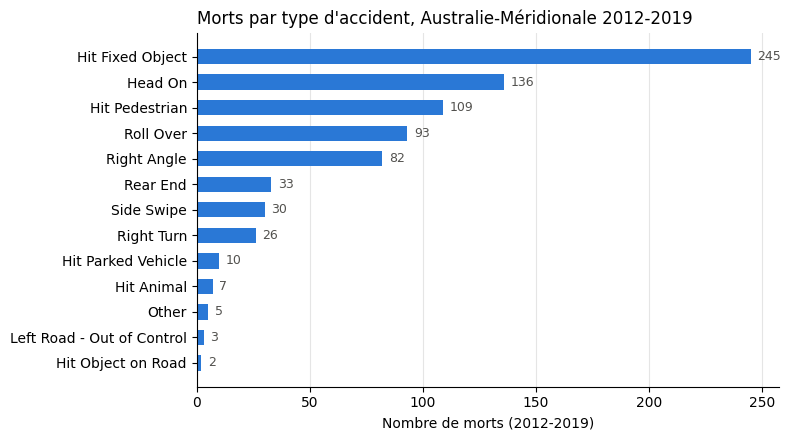

In [21]:
BLEU, ORANGE, VERT, JAUNE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # couleurs fixes des séries

def style_axes(ax):
    # Axes discrets : pas de cadre en haut et à droite, grille légère.
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)

d = morts_pd[morts_pd["Total fatalities"] > 0].sort_values("Total fatalities")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(d["Crash Type"], d["Total fatalities"], color=BLEU, height=0.6)
for y, v in enumerate(d["Total fatalities"]):
    ax.text(v + 3, y, str(v), va="center", fontsize=9, color="#52514e")
ax.set_xlabel("Nombre de morts (2012-2019)")
ax.set_title("Morts par type d'accident, Australie-Méridionale 2012-2019", loc="left")
style_axes(ax)
plt.tight_layout()
plt.show()

Les sorties de route contre un obstacle fixe (arbre, poteau...) sont de loin les plus meurtrières,
devant les collisions frontales et les piétons renversés.

**4. Le nombre de victimes par quartier quand le véhicule était conduit sans permis.**

L'information « sans permis » est dans la table des unités (`Licence Type = 'Unlicenced'`), le quartier et
le nombre de victimes dans celle des accidents. Il faut donc **joindre** les deux tables sur `REPORT_ID` :
chaque unité est complétée par les informations de son accident. Le résultat a une ligne par unité.

In [22]:
complete_df = crash_df.join(units_df, on="REPORT_ID", how="inner")
print("Lignes après la jointure :", complete_df.count(), "(une par unité)")

by_suburb_no_lic_df = (complete_df.filter(F.col("Licence Type") == "Unlicenced")
                       .groupBy("Suburb")
                       .agg(F.sum("Total Cas").alias("Total casualty")))
by_suburb_no_lic_df.orderBy(F.desc("Total casualty"), "Suburb").show(10)

sans_permis = {r["Suburb"]: r["Total casualty"] for r in by_suburb_no_lic_df.collect()}
verifier("Sans permis : ADELAIDE = article (43)", sans_permis["ADELAIDE"], 43)
verifier("Sans permis : SALISBURY = article (30)", sans_permis["SALISBURY"], 30)
verifier("Sans permis : PROSPECT = article (27)", sans_permis["PROSPECT"], 27)

Lignes après la jointure : 272591 (une par unité)


+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
| MORPHETT VALE|            20|
|SALISBURY EAST|            20|
|     DRY CREEK|            19|
| MURRAY BRIDGE|            19|
|  MAWSON LAKES|            17|
|NORTH ADELAIDE|            17|
+--------------+--------------+
only showing top 10 rows



OK    Sans permis : ADELAIDE = article (43)
OK    Sans permis : SALISBURY = article (30)
OK    Sans permis : PROSPECT = article (27)


True

On écrit `on="REPORT_ID"` plutôt que `crash_df.REPORT_ID == units_df.REPORT_ID` comme l'article : le
résultat ne garde alors qu'**une** colonne `REPORT_ID` au lieu de deux colonnes du même nom.

Attention à ce que mesure cette requête (reprise de l'article) : on additionne le `Total Cas` de
l'accident **pour chaque unité sans permis**. Si deux conducteurs sans permis sont dans le même accident,
ses victimes sont comptées deux fois. On mesure l'écart en partie 7.

## 5. Alcool, drogue et gravité des accidents

La colonne `CSEF Severity` donne la **gravité** de l'accident, d'après la blessure la plus grave :

| Code | Signification |
|---|---|
| `1: PDO` | *Property Damage Only* : dégâts matériels seulement |
| `2: MI` | *Minor Injury* : blessé léger |
| `3: SI` | *Serious Injury* : blessé grave |
| `4: Fatal` | au moins un mort |

`DUI Involved` vaut `Y` si au moins un conducteur avait un taux d'alcool illégal, `Drugs Involved` vaut
`Y` si au moins un conducteur a été contrôlé positif à la drogue. Sinon la case est vide.

**Question : les accidents sont-ils plus graves quand l'alcool ou la drogue sont en cause ?**

D'abord, le nombre d'accidents de chaque gravité, sur toute la période :

In [23]:
severe_df = crash_df.groupBy("CSEF Severity").agg(F.count("REPORT_ID").alias("Total accidents")).orderBy("CSEF Severity")
severe_df.show()
verifier("Accidents par gravité = article",
         {r[0]: r[1] for r in severe_df.collect()},
         {"1: PDO": 84775, "2: MI": 37300, "3: SI": 4875, "4: Fatal": 722})

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|       1: PDO|          84775|
|        2: MI|          37300|
|        3: SI|           4875|
|     4: Fatal|            722|
+-------------+---------------+



OK    Accidents par gravité = article


True

On compare quatre situations :

| | Situation | Condition |
|---|---|---|
| a | **Drogue** : un conducteur positif à la drogue | `Drugs Involved = 'Y'` |
| b | **Alcool** : un conducteur positif à l'alcool | `DUI Involved = 'Y'` |
| c | **Les deux** : drogue et alcool | les deux à `'Y'` |
| d | **Aucun** : ni drogue ni alcool | les deux vides |

Pour chaque situation, on compte les accidents par gravité, puis on calcule la **part** de chaque gravité
(en %). Ce sont les parts qu'il faut comparer : il y a bien plus d'accidents sans alcool ni drogue, donc
les nombres bruts ne se comparent pas.

L'auteur calcule le pourcentage avec une **UDF** (une fonction Python appelée sur chaque ligne). On le fait
avec une simple expression sur les colonnes, `F.round(100 * count / total, 2)` : Spark la calcule sans
passer par Python. La partie 8 compare les deux temps.

In [24]:
SCENARIOS = {
    "Drogue":   F.col("Drugs Involved") == "Y",
    "Alcool":   F.col("DUI Involved") == "Y",
    "Les deux": (F.col("Drugs Involved") == "Y") & (F.col("DUI Involved") == "Y"),
    "Aucun":    F.col("Drugs Involved").isNull() & F.col("DUI Involved").isNull(),
}

def repartition_gravite(condition):
    # Nombre d'accidents et part (en %) de chaque gravité, parmi les accidents qui vérifient `condition`.
    sous_ensemble = crash_df.filter(condition)
    total = sous_ensemble.count()
    return (sous_ensemble.groupBy("CSEF Severity").agg(F.count("REPORT_ID").alias("accidents"))
            .withColumn("part (%)", F.round(100 * F.col("accidents") / total, 2))
            .orderBy("CSEF Severity"))

resultats_gravite = {}
for nom, condition in SCENARIOS.items():
    print(f"--- {nom}")
    resultat = repartition_gravite(condition)
    resultat.show()
    resultats_gravite[nom] = resultat.toPandas().set_index("CSEF Severity")

--- Drogue


+-------------+---------+--------+
|CSEF Severity|accidents|part (%)|
+-------------+---------+--------+
|       1: PDO|      237|   12.78|
|        2: MI|     1109|   59.82|
|        3: SI|      391|   21.09|
|     4: Fatal|      117|    6.31|
+-------------+---------+--------+



--- Alcool


+-------------+---------+--------+
|CSEF Severity|accidents|part (%)|
+-------------+---------+--------+
|       1: PDO|     2144|   53.88|
|        2: MI|     1243|   31.24|
|        3: SI|      456|   11.46|
|     4: Fatal|      136|    3.42|
+-------------+---------+--------+



--- Les deux


+-------------+---------+--------+
|CSEF Severity|accidents|part (%)|
+-------------+---------+--------+
|       1: PDO|       36|   12.08|
|        2: MI|      151|   50.67|
|        3: SI|       72|   24.16|
|     4: Fatal|       39|   13.09|
+-------------+---------+--------+



--- Aucun


+-------------+---------+--------+
|CSEF Severity|accidents|part (%)|
+-------------+---------+--------+
|       1: PDO|    82430|   67.49|
|        2: MI|    35099|   28.74|
|        3: SI|     4100|    3.36|
|     4: Fatal|      508|    0.42|
+-------------+---------+--------+



On rassemble les quatre situations dans deux tableaux : les nombres d'accidents, puis les parts. Ils n'ont
que 4 lignes : `toPandas()` ne pose aucun problème.

L'auteur prévient que `toPandas()` peut faire planter la machine : il rapatrie tout le DataFrame dans un
seul programme Python, qui n'est plus distribué. On ne l'utilise donc que sur des **résultats déjà
agrégés**, jamais sur les données brutes.

In [25]:
nombres = pd.DataFrame({nom: r["accidents"] for nom, r in resultats_gravite.items()})
parts = pd.DataFrame({nom: r["part (%)"] for nom, r in resultats_gravite.items()})
display(nombres)
display(parts)

article_nombres = pd.DataFrame(
    {"Drogue": [237, 1109, 391, 117], "Alcool": [2144, 1243, 456, 136],
     "Les deux": [36, 151, 72, 39], "Aucun": [82430, 35099, 4100, 508]},
    index=["1: PDO", "2: MI", "3: SI", "4: Fatal"])
article_parts = pd.DataFrame(
    {"Drogue": [12.78, 59.82, 21.09, 6.31], "Alcool": [53.88, 31.24, 11.46, 3.42],
     "Les deux": [12.08, 50.67, 24.16, 13.09], "Aucun": [67.49, 28.74, 3.36, 0.42]},
    index=["1: PDO", "2: MI", "3: SI", "4: Fatal"])
verifier("Gravité x situation : nombres = article",
         nombres.loc[article_nombres.index, article_nombres.columns].astype(int).to_numpy().tolist(),
         article_nombres.to_numpy().tolist())
verifier("Gravité x situation : parts = article (à 0,01 près)",
         bool(((parts - article_parts).abs() <= 0.011).all().all()), True)

,Drogue,Alcool,Les deux,Aucun
CSEF Severity,,,,
1: PDO,237,2144,36,82430
2: MI,1109,1243,151,35099
3: SI,391,456,72,4100
4: Fatal,117,136,39,508


,Drogue,Alcool,Les deux,Aucun
CSEF Severity,,,,
1: PDO,12.78,53.88,12.08,67.49
2: MI,59.82,31.24,50.67,28.74
3: SI,21.09,11.46,24.16,3.36
4: Fatal,6.31,3.42,13.09,0.42


OK    Gravité x situation : nombres = article
OK    Gravité x situation : parts = article (à 0,01 près)


True

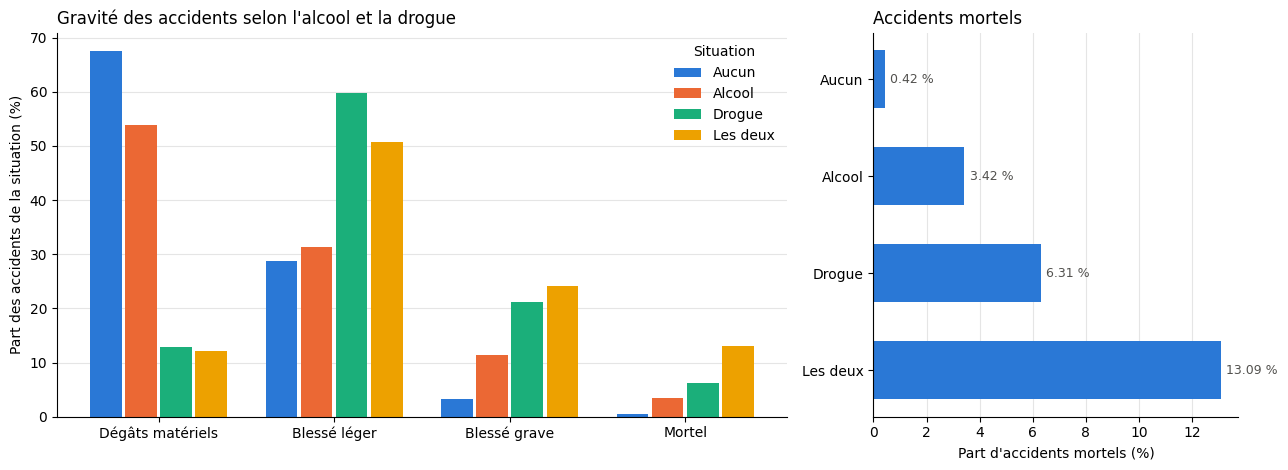

Part des accidents mortels, comparée à « Aucun » :
  Alcool   :  3.42 %  soit  8.1 fois plus
  Drogue   :  6.31 %  soit 15.0 fois plus
  Les deux : 13.09 %  soit 31.2 fois plus


In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [2, 1]})

# À gauche : part de chaque gravité, pour les quatre situations
couleurs = {"Aucun": BLEU, "Alcool": ORANGE, "Drogue": VERT, "Les deux": JAUNE}
gravites = ["1: PDO", "2: MI", "3: SI", "4: Fatal"]
largeur = 0.2
for k, (nom, couleur) in enumerate(couleurs.items()):
    x = [i + (k - 1.5) * largeur for i in range(len(gravites))]
    ax1.bar(x, parts.loc[gravites, nom], width=largeur * 0.9, color=couleur, label=nom)
ax1.set_xticks(range(len(gravites)))
ax1.set_xticklabels(["Dégâts matériels", "Blessé léger", "Blessé grave", "Mortel"])
ax1.set_ylabel("Part des accidents de la situation (%)")
ax1.set_title("Gravité des accidents selon l'alcool et la drogue", loc="left")
ax1.legend(title="Situation", frameon=False)
style_axes(ax1); ax1.grid(axis="x", visible=False); ax1.grid(axis="y", color="#e5e5e5", linewidth=0.8)

# À droite : la part des accidents mortels seule, plus lisible
mortels = parts.loc["4: Fatal", list(couleurs)]
ax2.barh(list(couleurs), mortels, color=BLEU, height=0.6)
for y, v in enumerate(mortels):
    ax2.text(v + 0.2, y, f"{v:.2f} %", va="center", fontsize=9, color="#52514e")
ax2.invert_yaxis()
ax2.set_xlabel("Part d'accidents mortels (%)")
ax2.set_title("Accidents mortels", loc="left")
style_axes(ax2)
plt.tight_layout()
plt.show()

print("Part des accidents mortels, comparée à « Aucun » :")
for nom in ["Alcool", "Drogue", "Les deux"]:
    print(f"  {nom:9s}: {parts.loc['4: Fatal', nom]:5.2f} %  soit {parts.loc['4: Fatal', nom] / parts.loc['4: Fatal', 'Aucun']:4.1f} fois plus")

**Lecture :**

- Sans alcool ni drogue, deux accidents enregistrés sur trois ne font **que des dégâts matériels**, et
  moins d'un sur deux cents est mortel.
- Avec de l'alcool, la part d'accidents mortels est environ **8 fois** plus forte. Avec de la drogue,
  environ **15 fois**. Avec les deux, environ **30 fois** : plus d'un accident sur huit est mortel.
- La drogue est surtout associée aux blessés (légers et graves), l'alcool reste plus souvent associé à des
  dégâts matériels.

**Prudence :** ce sont des **corrélations**, pas une preuve de cause à effet. D'une part, les accidents
avec seulement des dégâts matériels ne sont pas tous enregistrés (seulement ceux avec un véhicule
remorqué, une moto, un poids lourd... selon les règles du DPTI). D'autre part, les dépistages ne sont sans
doute pas faits de la même façon pour tous les accidents : un accident grave donne plus souvent lieu à un
contrôle. Ces deux effets peuvent gonfler la part des accidents graves dans les situations « alcool » et
« drogue ».

## 6. Une même requête écrite trois fois : RDD, DataFrame, SparkSQL

L'article montre que Spark permet d'écrire la même requête de trois façons :

| | RDD | DataFrame | SparkSQL |
|---|---|---|---|
| On écrit | des fonctions Python appliquées à chaque ligne | des opérations sur des colonnes | une requête SQL |
| Colonnes | par leur position (`ligne[8]`) | par leur nom | par leur nom |
| Qui calcule | des processus Python | Java, après optimisation | Java, après optimisation |

Pour SparkSQL, on donne d'abord un nom de table à chaque DataFrame avec `createOrReplaceTempView`. On peut
alors l'interroger en SQL avec `spark.sql(...)`.

On écrit les deux requêtes de l'article dans les trois styles, puis on **vérifie que les trois donnent
exactement le même résultat**.

In [27]:
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")

def vide_en_none(valeur):
    # Une case vide vaut "" dans un RDD lu avec textFile, et null (None) dans un DataFrame.
    return valeur if valeur != "" else None

def en_ensemble(lignes):
    # Liste de lignes -> liste triée de tuples, pour comparer deux résultats sans tenir compte de l'ordre.
    return sorted((tuple(l) for l in lignes), key=repr)

### 6.1 Requête A : détail des accidents du quartier d'Adélaïde

Pour chaque unité impliquée dans un accident du quartier `ADELAIDE` : la date (`Année-Mois-Jour de la
semaine`), l'heure, le nombre de victimes dans l'unité, le sexe, l'âge et le type de permis du conducteur.

**Version RDD.** Pour joindre deux RDD, chacun doit être une liste de paires `(clé, valeur)` avec la même
clé, ici `REPORT_ID`. On filtre les accidents d'Adélaïde **avant** la jointure : il y a moins de lignes à
joindre.

In [28]:
def requete_a_rdd():
    accidents = (crash_champs
        .filter(lambda c: c[CC["Suburb"]] == "ADELAIDE")
        .map(lambda c: (c[CC["REPORT_ID"]],
                        (c[CC["Year"]] + "-" + c[CC["Month"]] + "-" + c[CC["Day"]], c[CC["Time"]], c[CC["Suburb"]]))))
    unites = units_champs.map(lambda u: (u[CU["REPORT_ID"]],
                                         (int(u[CU["No Of Cas"]]), u[CU["Sex"]], u[CU["Age"]], u[CU["Licence Type"]])))
    # après la jointure : (REPORT_ID, ((date, heure, quartier), (victimes, sexe, âge, permis)))
    return (accidents.join(unites)
            .map(lambda kv: (kv[1][0][0], kv[1][0][1], kv[1][1][0],
                             vide_en_none(kv[1][1][1]), vide_en_none(kv[1][1][2]),
                             vide_en_none(kv[1][1][3]), kv[1][0][2]))
            .collect())

resultat_a_rdd = requete_a_rdd()
print(len(resultat_a_rdd), "lignes. Exemples :")
for ligne in resultat_a_rdd[:3]:
    print(" ", ligne)

11965 lignes. Exemples :
  ('2012-April-Friday', '02:10 pm', 0, 'Female', '018', 'Provisional 1 ', 'ADELAIDE')
  ('2012-April-Friday', '02:10 pm', 0, 'Unknown', 'XXX', None, 'ADELAIDE')
  ('2012-May-Friday', '05:00 pm', 0, 'Male', '027', 'Full', 'ADELAIDE')


**Version DataFrame.** `F.concat_ws("-", ...)` colle les colonnes avec un tiret. L'article passe par une
UDF Python pour construire la date : une fonction intégrée fait la même chose, sans Python.

In [29]:
def requete_a_df():
    return (crash_df.filter(F.col("Suburb") == "ADELAIDE")
            .join(units_df, on="REPORT_ID")
            .select(F.concat_ws("-", "Year", "Month", "Day").alias("Date"), "Time", "No Of Cas",
                    "Sex", "Age", "Licence Type", "Suburb"))

requete_a_df().show(5, truncate=False)
resultat_a_df = requete_a_df().collect()

+-------------------+--------+---------+------+---+-------------+--------+
|Date               |Time    |No Of Cas|Sex   |Age|Licence Type |Suburb  |
+-------------------+--------+---------+------+---+-------------+--------+
|2012-January-Monday|08:45 am|0        |Male  |084|Full         |ADELAIDE|
|2012-January-Monday|08:45 am|0        |Male  |040|Full         |ADELAIDE|
|2012-January-Friday|05:45 pm|0        |Male  |047|Full         |ADELAIDE|
|2012-January-Friday|05:45 pm|0        |Male  |XXX|NULL         |ADELAIDE|
|2012-January-Friday|07:30 pm|0        |Female|018|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+---+-------------+--------+
only showing top 5 rows



**Version SparkSQL.** En SQL, `||` colle des textes. Les noms de colonnes qui contiennent un espace
s'écrivent entre accents graves : `` `Total Cas` ``.

In [30]:
REQUETE_A_SQL = """
    SELECT c.Year || '-' || c.Month || '-' || c.Day AS Date, c.Time, u.`No Of Cas`,
           u.Sex, u.Age, u.`Licence Type`, c.Suburb
    FROM crash_table c JOIN units_table u ON u.REPORT_ID = c.REPORT_ID
    WHERE c.Suburb = 'ADELAIDE'
"""
def requete_a_sql():
    return spark.sql(REQUETE_A_SQL)

requete_a_sql().show(5, truncate=False)
resultat_a_sql = requete_a_sql().collect()

+-------------------+--------+---------+------+---+-------------+--------+
|Date               |Time    |No Of Cas|Sex   |Age|Licence Type |Suburb  |
+-------------------+--------+---------+------+---+-------------+--------+
|2012-January-Monday|08:45 am|0        |Male  |084|Full         |ADELAIDE|
|2012-January-Monday|08:45 am|0        |Male  |040|Full         |ADELAIDE|
|2012-January-Friday|05:45 pm|0        |Male  |047|Full         |ADELAIDE|
|2012-January-Friday|05:45 pm|0        |Male  |XXX|NULL         |ADELAIDE|
|2012-January-Friday|07:30 pm|0        |Female|018|Provisional 2|ADELAIDE|
+-------------------+--------+---------+------+---+-------------+--------+
only showing top 5 rows



In [31]:
print("Lignes : RDD", len(resultat_a_rdd), "| DataFrame", len(resultat_a_df), "| SQL", len(resultat_a_sql))
verifier("Requête A : RDD = DataFrame", en_ensemble(resultat_a_rdd), en_ensemble(resultat_a_df))
verifier("Requête A : SQL = DataFrame", en_ensemble(resultat_a_sql), en_ensemble(resultat_a_df))

Lignes : RDD 11965 | DataFrame 11965 | SQL 11965
OK    Requête A : RDD = DataFrame


OK    Requête A : SQL = DataFrame


True

### 6.2 Requête B : victimes par quartier quand le conducteur n'a pas de permis

C'est la requête 4 de la partie 4, reprise dans les trois styles.

In [32]:
def requete_b_rdd():
    victimes = crash_champs.map(lambda c: (c[CC["REPORT_ID"]], (vide_en_none(c[CC["Suburb"]]), int(c[CC["Total Cas"]]))))
    sans_permis = (units_champs.filter(lambda u: u[CU["Licence Type"]] == "Unlicenced")
                   .map(lambda u: (u[CU["REPORT_ID"]], 1)))
    # après la jointure : (REPORT_ID, (1, (quartier, victimes))) ; on garde (quartier, victimes)
    return dict(sans_permis.join(victimes).map(lambda kv: kv[1][1]).reduceByKey(add).collect())

def requete_b_df():
    return (crash_df.join(units_df, on="REPORT_ID")
            .filter(F.col("Licence Type") == "Unlicenced")
            .groupBy("Suburb").agg(F.sum("Total Cas").alias("Total casualty")))

REQUETE_B_SQL = """
    SELECT c.Suburb, SUM(c.`Total Cas`) AS `Total casualty`
    FROM crash_table c JOIN units_table u ON u.REPORT_ID = c.REPORT_ID
    WHERE u.`Licence Type` = 'Unlicenced'
    GROUP BY c.Suburb
"""
def requete_b_sql():
    return spark.sql(REQUETE_B_SQL)

resultat_b_rdd = requete_b_rdd()
resultat_b_df = {r[0]: r[1] for r in requete_b_df().collect()}
resultat_b_sql = {r[0]: r[1] for r in requete_b_sql().collect()}

print("Quartiers : RDD", len(resultat_b_rdd), "| DataFrame", len(resultat_b_df), "| SQL", len(resultat_b_sql))
print("ADELAIDE  : RDD", resultat_b_rdd["ADELAIDE"], "| DataFrame", resultat_b_df["ADELAIDE"], "| SQL", resultat_b_sql["ADELAIDE"])
verifier("Requête B : RDD = DataFrame", resultat_b_rdd, resultat_b_df)
verifier("Requête B : SQL = DataFrame", resultat_b_sql, resultat_b_df)
verifier("Requête B : DataFrame = requête 4 de la partie 4", resultat_b_df, sans_permis)

Quartiers : RDD 752 | DataFrame 752 | SQL 752
ADELAIDE  : RDD 43 | DataFrame 43 | SQL 43
OK    Requête B : RDD = DataFrame
OK    Requête B : SQL = DataFrame
OK    Requête B : DataFrame = requête 4 de la partie 4


True

### 6.3 Ce que donnait le code de l'article

Dans l'article, les versions RDD, DataFrame et SQL de ces deux requêtes ne donnent **pas** toutes le même
résultat. On exécute
son code tel quel pour le montrer.

**Requête A, version RDD de l'article.** Il découpe les lignes avec `split(',')` puis enlève la première
colonne (`array_line[1:]`) : l'indice `k` du reste correspond donc à la colonne `k + 1` du fichier. Ses
indices sont décalés d'un cran.

In [33]:
def parseKey(line):                                    # code de l'article
    array_line = [value.replace('"', '') for value in line.split(',')]
    return (array_line[0], array_line[1:])

def parseRecord1(line):                                # code de l'article
    if line[1][1][1] == 'ADELAIDE':
        return [line[1][1][1], line[1][0][7], line[1][0][8], line[1][0][11],
                line[1][1][12], line[1][1][6], line[1][1][9] + "-" + line[1][1][10] + "-" + line[1][1][11]]

# Seul ajout au code de l'article : cache(), pour ne pas redécouper les lignes à chaque requête
units_cle = units_rdd.map(parseKey).cache()
crash_cle = crash_rdd.map(parseKey).cache()

ligne_article = (units_cle.join(crash_cle)
                 .map(parseRecord1).filter(lambda x: x is not None).first())

# indice k du reste de la ligne = colonne k + 1 du fichier
noms_u = lire_ligne(units_header); noms_c = lire_ligne(crash_header)
pd.DataFrame({
    "champ voulu":         ["Suburb", "Sex", "Age", "Licence Type", "Time", "Total Cas", "Date"],
    "colonne réellement lue": [noms_c[2], noms_u[8], noms_u[9], noms_u[12], noms_c[13], noms_c[7],
                               f"{noms_c[10]}-{noms_c[11]}-{noms_c[12]}"],
    "valeur obtenue":      ligne_article,
})

,champ voulu,colonne réellement lue,valeur obtenue
0,Suburb,Suburb,ADELAIDE
1,Sex,Age,018
2,Age,Lic State,SA
3,Licence Type,Towing,Unknown
4,Time,Time,02:10 pm
5,Total Cas,Total Fats,0
6,Date,Year-Month-Day,2012-April-Friday


Le quartier, l'heure et la date sont justes, mais au lieu du sexe, de l'âge, du type de permis et du
nombre de victimes, le code lit l'âge, l'État du permis, la colonne « remorquage » et le nombre de morts.

**Requête B, les trois versions de l'article.** Elles ne calculent pas la même chose, et aucune ne garde
les conducteurs **sans** permis :
- RDD : somme des victimes des unités dont le permis est **connu** ;
- DataFrame : **nombre de lignes** (`count` de `No Of Cas`) des unités dont le permis est connu ;
- SQL : nombre de lignes aussi, avec un filtre écrit autrement ; sur ces données, il donne le même
  résultat que la version DataFrame.

In [34]:
def requete_b_article_rdd():                           # code de l'article
    joined_rdd = units_cle.join(crash_cle)
    filtered_rdd = joined_rdd.filter(lambda x: (x[1][0][9] != "XX") & (x[1][0][8] != "UNKNOWN") & (x[1][0][10] != "Unknown")
                                     & (x[1][0][9] is not None) & (x[1][0][10] is not None) & (x[1][0][11] is not None))
    return dict(filtered_rdd.map(lambda line: (line[1][1][1], int(line[1][1][5]))).groupByKey().mapValues(sum).collect())

def requete_b_article_df():                            # code de l'article
    joined_df = crash_df.join(units_df, crash_df.REPORT_ID == units_df.REPORT_ID, how='inner')
    without_lic_df = joined_df.dropna(subset=('Licence Type', 'Licence Class', 'Lic State'), how='all')
    return {r[0]: r[1] for r in without_lic_df.filter((F.col('Licence Type') != 'Unknown') & (F.col('Licence Class') != 'XX')
            & (F.col('Lic State') != 'UNKNOWN')).groupby('Suburb').agg(F.count('No Of Cas').alias('Total casualty')).collect()}

def requete_b_article_sql():                           # code de l'article
    return {r[0]: r[1] for r in spark.sql("""
        SELECT Suburb, COUNT(`Total Cas`) FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
        WHERE `Lic State` IS NOT NULL and `Licence Class` IS NOT NULL and `Licence Type` IS NOT NULL and
              `Licence Type` != 'Unknown' and `Licence Class` != 'XX' and `Lic State` != 'UNKNOWN'
        GROUP BY Suburb""").collect()}

comparaison_article = pd.DataFrame({
    "article RDD": requete_b_article_rdd(),
    "article DataFrame": requete_b_article_df(),
    "article SQL": requete_b_article_sql(),
    "notre version (les 3 identiques)": resultat_b_df,
}).loc[["ADELAIDE", "SALISBURY", "PROSPECT", "INGLE FARM"]]
comparaison_article

,article RDD,article DataFrame,article SQL,notre version (les 3 identiques)
ADELAIDE,3935.0,7514.0,7514.0,43.0
SALISBURY,803.0,1380.0,1380.0,30.0
PROSPECT,1262.0,2448.0,2448.0,27.0
INGLE FARM,678.0,1153.0,1153.0,22.0


**Ce qu'on a corrigé par rapport à l'article :**

| Endroit | Dans l'article | Problème | Dans ce notebook |
|---|---|---|---|
| Lecture des accidents en RDD | `line.split(',')` | une ligne sur six est décalée (virgules entre guillemets) | module `csv` (`lire_ligne`) |
| Colonnes en RDD | indices écrits à la main | requête A : décalage d'un cran, mauvaises colonnes | indices retrouvés par le nom (`CU["Age"]`) |
| Requête B (3 versions) | trois filtres et deux calculs différents | RDD et DataFrame/SQL ne donnent pas le même résultat, et aucun ne porte sur les conducteurs sans permis | une seule définition, résultats identiques (testé) |
| Moyenne par sexe | `groupByKey` | fait circuler tous les âges | `reduceByKey` : sous-totaux par partition |
| Pourcentages, dates | UDF Python | les données passent par Python | expressions Spark (`F.round`, `concat_ws`) |
| Résultats | `collect()[0:5]`, `glom().collect()` | rapatrie toutes les données | `take(5)`, `glom().map(len)` |

## 7. Tests : vérification par un autre outil (pandas)

Comparer RDD, DataFrame et SQL ne suffit pas : les trois passent par Spark et lisent les fichiers de la
même façon. On refait donc les calculs principaux avec **pandas**, une bibliothèque Python indépendante
de Spark. Les données tiennent en mémoire (80 Mo), c'est possible ici.

In [35]:
def lire_pandas(dossier):
    return pd.concat([pd.read_csv(f, dtype=str) for f in sorted((DATA_DIR / dossier).glob("*.csv"))],
                     ignore_index=True)

t0 = time.perf_counter()
crash_pd = lire_pandas("crash_data")
units_pd = lire_pandas("units_data")
for colonne in ["Total Cas", "Total Fats"]:
    crash_pd[colonne] = crash_pd[colonne].astype(int)
units_pd["No Of Cas"] = units_pd["No Of Cas"].astype(int)
t_lecture_pandas = time.perf_counter() - t0
print(f"Lecture pandas : {t_lecture_pandas:.2f} s")

# Nombres de lignes
verifier("pandas : nombre d'accidents = Spark", len(crash_pd), n_crash)
verifier("pandas : nombre d'unités = Spark", len(units_pd), n_units)
verifier("pandas : chaque REPORT_ID est unique dans les accidents", crash_pd["REPORT_ID"].is_unique, True)
verifier("pandas : chaque unité a son accident", bool(units_pd["REPORT_ID"].isin(crash_pd["REPORT_ID"]).all()), True)

# Âge moyen par sexe
u = units_pd[units_pd["Age"].notna() & (units_pd["Age"] != "XXX") & units_pd["Sex"].notna() & (units_pd["Sex"] != "Unknown")]
verifier("pandas : âge moyen par sexe = Spark",
         u.assign(Age=u["Age"].astype(int)).groupby("Sex")["Age"].mean().round(2).to_dict(), age_moyen)

# Morts par type d'accident
verifier("pandas : morts par type d'accident = Spark",
         crash_pd.groupby("Crash Type")["Total Fats"].sum().to_dict(), morts)

# Gravité x situation
drogue, alcool = crash_pd["Drugs Involved"] == "Y", crash_pd["DUI Involved"] == "Y"
situations_pd = {"Drogue": drogue, "Alcool": alcool, "Les deux": drogue & alcool,
                 "Aucun": crash_pd["Drugs Involved"].isna() & crash_pd["DUI Involved"].isna()}
nombres_pd = pd.DataFrame({nom: crash_pd[masque].groupby("CSEF Severity").size() for nom, masque in situations_pd.items()})
verifier("pandas : gravité x situation = Spark", nombres_pd.to_dict(), nombres.to_dict())

Lecture pandas : 2.69 s
OK    pandas : nombre d'accidents = Spark
OK    pandas : nombre d'unités = Spark
OK    pandas : chaque REPORT_ID est unique dans les accidents
OK    pandas : chaque unité a son accident


OK    pandas : âge moyen par sexe = Spark
OK    pandas : morts par type d'accident = Spark
OK    pandas : gravité x situation = Spark


True

In [36]:
def requete_a_pandas():
    c = crash_pd[crash_pd["Suburb"] == "ADELAIDE"]
    j = c.merge(units_pd, on="REPORT_ID")
    j = j.assign(Date=j["Year"] + "-" + j["Month"] + "-" + j["Day"])
    return j[["Date", "Time", "No Of Cas", "Sex", "Age", "Licence Type", "Suburb"]]

def requete_b_pandas():
    j = crash_pd.merge(units_pd[units_pd["Licence Type"] == "Unlicenced"], on="REPORT_ID")
    return j.groupby("Suburb", dropna=False)["Total Cas"].sum().to_dict()

# même forme que les lignes Spark : victimes en int, cases vides en None
lignes_a_pd = [(date, heure, int(victimes), *[None if pd.isna(v) else v for v in reste])
               for date, heure, victimes, *reste in requete_a_pandas().itertuples(index=False)]
verifier("pandas : requête A = Spark", en_ensemble(lignes_a_pd), en_ensemble(resultat_a_df))
b_pd = {(None if pd.isna(k) else k): int(v) for k, v in requete_b_pandas().items()}
verifier("pandas : requête B = Spark", b_pd, resultat_b_df)

OK    pandas : requête A = Spark
OK    pandas : requête B = Spark


True

### Le double comptage de la requête B

La requête B (comme dans l'article) additionne les victimes de l'accident **une fois par conducteur sans
permis**. Une version plus juste compte chaque accident une seule fois : on prend la liste des accidents
qui ont **au moins un** conducteur sans permis (`distinct`), puis on additionne leurs victimes.

In [37]:
accidents_sans_permis = units_df.filter(F.col("Licence Type") == "Unlicenced").select("REPORT_ID").distinct()
version_juste = {r[0]: r[1] for r in (crash_df.join(accidents_sans_permis, on="REPORT_ID")
                                      .groupBy("Suburb").agg(F.sum("Total Cas")).collect())}

ecarts = {q: (resultat_b_df[q], version_juste[q]) for q in resultat_b_df if resultat_b_df[q] != version_juste[q]}
print("Accidents avec au moins un conducteur sans permis :", accidents_sans_permis.count())
print("Unités sans permis                                :", units_df.filter(F.col("Licence Type") == "Unlicenced").count())
print("Victimes, une fois par unité sans permis          :", sum(resultat_b_df.values()))
print("Victimes, une fois par accident                   :", sum(version_juste.values()))
print("Quartiers dont le total change                    :", len(ecarts), "sur", len(resultat_b_df))
print("Exemples (par unité, par accident) :", dict(list(sorted(ecarts.items(), key=lambda kv: -kv[1][0]))[:5]))

Accidents avec au moins un conducteur sans permis : 3887


Unités sans permis                                : 3926
Victimes, une fois par unité sans permis          : 2072
Victimes, une fois par accident                   : 2053
Quartiers dont le total change                    : 16 sur 752
Exemples (par unité, par accident) : {'ADELAIDE': (43, 42), 'SALISBURY EAST': (20, 19), 'SALISBURY NORTH': (11, 10), 'EDWARDSTOWN': (8, 7), 'MELROSE PARK': (8, 7)}


### Bilan des tests

In [38]:
bilan = pd.DataFrame(TESTS)
print(f"{(bilan['résultat'] == 'OK').sum()} tests réussis sur {len(bilan)}")
bilan

36 tests réussis sur 36


,test,résultat,obtenu,attendu
0,RDD : nombre d'unités = article,OK,272591,272591
1,RDD : nombre d'accidents = article,OK,127672,127672
2,RDD : les 8 en-têtes d'unités sont enlevés,OK,272591,272591
3,RDD : les 8 en-têtes d'accidents sont enlevés,OK,127672,127672
4,Partition SA = article (218 366),OK,218366,218366
5,Partition autres États = article (54 225),OK,54225,54225
6,Âge moyen par sexe = article,OK,"{'Male': 40.8, 'Female': 40.08}","{'Male': 40.8, 'Female': 40.08}"
7,Année du véhicule le plus ancien = article (1900),OK,1900,1900
8,Année du véhicule le plus récent = article (2019),OK,2019,2019
9,DataFrame : nombre d'unités = RDD,OK,272591,272591


## 8. Comparaison des temps

On chronomètre les deux requêtes de la partie 6 avec les quatre méthodes : RDD, DataFrame, SparkSQL et
pandas. Pour être juste :

- les données sont **en cache** en mémoire (`cache()`) : les RDD le sont depuis la partie 3.4, on fait
  de même pour les DataFrames. On mesure ainsi le calcul, pas la relecture des fichiers ;
- chaque mesure est répétée 3 fois et on garde **le meilleur temps** (le moins perturbé) ;
- la session Spark est déjà démarrée (ce temps, mesuré en partie 2, est payé une seule fois).

In [39]:
t0 = time.perf_counter()
crash_df = crash_df.cache(); units_df = units_df.cache()
crash_df.count(); units_df.count()
crash_df.createOrReplaceTempView("crash_table"); units_df.createOrReplaceTempView("units_table")
print(f"Mise en cache des DataFrames Spark : {time.perf_counter() - t0:.1f} s")
print(f"Lecture pandas (pour comparaison)  : {t_lecture_pandas:.1f} s")

def chrono(f, repetitions=3):
    # Meilleur temps (en secondes) sur `repetitions` exécutions de f().
    temps = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        f()
        temps.append(time.perf_counter() - t0)
    return min(temps)

methodes = {
    "Requête A": {"RDD": requete_a_rdd, "DataFrame": lambda: requete_a_df().collect(),
                  "SparkSQL": lambda: requete_a_sql().collect(), "pandas": requete_a_pandas},
    "Requête B": {"RDD": requete_b_rdd, "DataFrame": lambda: requete_b_df().collect(),
                  "SparkSQL": lambda: requete_b_sql().collect(), "pandas": requete_b_pandas},
}
temps = pd.DataFrame({requete: {nom: chrono(f) for nom, f in fs.items()} for requete, fs in methodes.items()})
temps.round(3)

Mise en cache des DataFrames Spark : 2.8 s
Lecture pandas (pour comparaison)  : 2.7 s


,Requête A,Requête B
RDD,47.275,137.451
DataFrame,0.267,1.746
SparkSQL,0.154,1.697
pandas,0.106,0.109


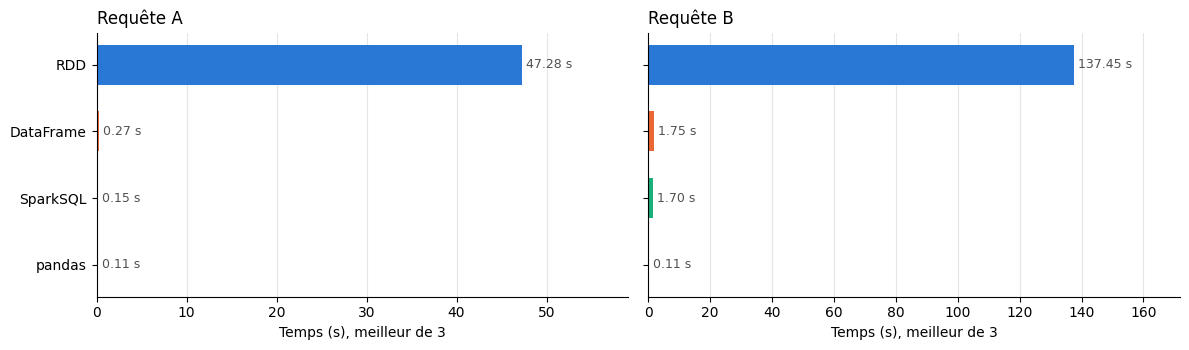

RDD / DataFrame : {'Requête A': 176.9, 'Requête B': 78.7}
DataFrame / pandas : {'Requête A': 2.5, 'Requête B': 16.1}


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
couleurs_methodes = {"RDD": BLEU, "DataFrame": ORANGE, "SparkSQL": VERT, "pandas": JAUNE}
for ax, requete in zip(axes, temps.columns):
    valeurs = temps[requete].loc[list(couleurs_methodes)]
    ax.barh(list(couleurs_methodes), valeurs, color=list(couleurs_methodes.values()), height=0.6)
    for y, v in enumerate(valeurs):
        ax.text(v, y, f" {v:.2f} s", va="center", fontsize=9, color="#52514e")
    ax.set_title(requete, loc="left")
    ax.set_xlabel("Temps (s), meilleur de 3")
    ax.set_xlim(0, valeurs.max() * 1.25)
    style_axes(ax)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

print("RDD / DataFrame :", (temps.loc["RDD"] / temps.loc["DataFrame"]).round(1).to_dict())
print("DataFrame / pandas :", (temps.loc["DataFrame"] / temps.loc["pandas"]).round(1).to_dict())

### Pourquoi DataFrame et SparkSQL vont aussi vite : le même plan

Une requête DataFrame et une requête SQL passent par le même optimiseur, qui en tire un **plan
d'exécution**. `explain()` l'affiche. Si les deux plans sont identiques, Spark fait exactement le même
travail. (On enlève les numéros internes des colonnes, `#123`, et des étapes, `plan_id=...`, qui changent
d'une requête à l'autre.)

In [41]:
def plan(df):
    texte = df._jdf.queryExecution().executedPlan().toString()
    return re.sub(r"#\d+L?|plan_id=\d+", "", texte)

requete_b_sql().explain()
verifier("Requête B : DataFrame et SQL ont le même plan d'exécution",
         plan(requete_b_df()), plan(requete_b_sql()))

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[Suburb#111], functions=[sum(Total Cas#175)])
   +- Exchange hashpartitioning(Suburb#111, 200), ENSURE_REQUIREMENTS, [plan_id=4758]
      +- HashAggregate(keys=[Suburb#111], functions=[partial_sum(Total Cas#175)])
         +- Project [Suburb#111, Total Cas#175]
            +- BroadcastHashJoin [REPORT_ID#109], [REPORT_ID#36], Inner, BuildRight, false
               :- Filter isnotnull(REPORT_ID#109)
               :  +- InMemoryTableScan [REPORT_ID#109, Suburb#111, Total Cas#175], [isnotnull(REPORT_ID#109)]
               :        +- InMemoryRelation [REPORT_ID#109, Stats Area#110, Suburb#111, Postcode#112, LGA Name#113, Total Units#114, Total Cas#175, Total Fats#210, Total SI#117, Total MI#118, Year#119, Month#120, Day#121, Time#122, Area Speed#123, Position Type#124, Horizontal Align#125, Vertical Align#126, Other Feat#127, Road Surface#128, Moisture Cond#129, Weather Cond#130, DayNight#131, Crash Type#132,

OK    Requête B : DataFrame et SQL ont le même plan d'exécution


True

### UDF Python ou expression Spark

Dernière comparaison : le calcul des pourcentages de la partie 5, avec une UDF Python (méthode de
l'article) ou avec une expression Spark (notre méthode). On le fait sur la situation « Aucun »
(122 000 accidents), en appliquant le calcul **à chaque accident** pour que la différence se voie :
avec l'UDF, chaque ligne part dans un processus Python et revient.

In [42]:
aucun = crash_df.filter(SCENARIOS["Aucun"]).cache()
total_aucun = aucun.count()

def part_udf(s):                                       # style de l'article
    return float(round((int(s) / total_aucun) * 100, 6))
part_udf_spark = udf(part_udf, FloatType())

avec_udf = lambda: aucun.select(F.sum(part_udf_spark("Total Cas"))).first()
avec_expression = lambda: aucun.select(F.sum(F.round(100 * F.col("Total Cas") / total_aucun, 6))).first()

temps_udf = pd.Series({"UDF Python": chrono(avec_udf), "expression Spark": chrono(avec_expression)})
print(temps_udf.round(3).to_string())
print(f"L'UDF est {temps_udf['UDF Python'] / temps_udf['expression Spark']:.0f} fois plus lente")
verifier("UDF et expression donnent la même somme (à 0,01 près)",
         abs(avec_udf()[0] - avec_expression()[0]) < 0.01, True)

UDF Python          18.754
expression Spark     0.651
L'UDF est 29 fois plus lente


OK    UDF et expression donnent la même somme (à 0,01 près)


True

### Ce que disent les mesures

Les chiffres exacts dépendent de la machine ; les écarts entre méthodes, eux, se retrouvent d'une
exécution à l'autre.

- **RDD contre DataFrame/SQL.** Les RDD sont plusieurs fois plus lents : chaque ligne est envoyée à un
  processus Python, traitée par nos `lambda`, puis renvoyée à Java. Les DataFrames restent dans Java et
  profitent de l'optimiseur.
- **DataFrame contre SparkSQL.** Même plan d'exécution, donc mêmes temps (aux variations de mesure près).
  On choisit l'écriture qu'on préfère.
- **UDF Python.** Même problème que les RDD, à plus petite échelle : une fonction Python appelée sur
  chaque ligne coûte cher. Quand une fonction Spark existe (`F.round`, `concat_ws`...), on l'utilise.
- **pandas.** Sur 80 Mo de données qui tiennent en mémoire, pandas est le plus rapide : Spark paie des
  frais fixes (planifier le calcul, lancer des tâches, regrouper les résultats) qui ne sont pas rentables
  sur un si petit volume. L'intérêt de Spark apparaît quand les données ne tiennent plus dans la mémoire
  d'une machine, ou qu'on les répartit sur un cluster : le même code passe alors de `local[*]` à des
  dizaines de machines, ce que pandas ne sait pas faire.

## 9. Conclusion

### Ce que disent les données

- **127 672 accidents** et **272 591 unités** (véhicules, piétons) en Australie-Méridionale de 2012 à 2019.
  Deux accidents sur trois ne font que des dégâts matériels ; 722 sont mortels.
- **Les obstacles fixes tuent le plus** : 245 morts en heurtant un arbre, un poteau ou un mur, devant les
  collisions frontales (136) et les piétons renversés (109).
- **L'alcool et la drogue rendent les accidents beaucoup plus graves.** Sans l'un ni l'autre, 0,42 % des
  accidents sont mortels. Avec de l'alcool : 3,42 % (8 fois plus). Avec de la drogue : 6,31 % (15 fois
  plus). Avec les deux : 13,09 % (31 fois plus).
- Les conducteurs ont en moyenne 40,8 ans (hommes) et 40,1 ans (femmes). Adélaïde est le quartier qui
  compte le plus de victimes dans les accidents avec un conducteur sans permis (43).

### Ce que dit l'outil

- **Les trois écritures donnent le même résultat** quand on les écrit correctement : RDD, DataFrame et
  SparkSQL trouvent les mêmes 11 965 lignes pour la requête A et les mêmes totaux sur 752 quartiers pour la
  requête B.
- **DataFrame et SparkSQL sont la même chose** pour Spark : même plan d'exécution, donc mêmes temps.
  On choisit l'écriture la plus lisible.
- **Les RDD sont les plus lents et les plus fragiles.** On manipule des listes de champs à la main : le
  code de l'article se trompe d'indice, et `split(',')` décale une ligne d'accident sur six. Les DataFrames
  lisent le CSV correctement et nomment les colonnes.
- **Une UDF Python coûte cher** : ici 29 fois plus lente. Une expression Spark fait le même calcul sans passer par Python.
- **Sur 80 Mo, pandas est le plus rapide** : environ 0,1 s par requête, contre 0,15 à 1,7 s pour les DataFrames et 47 à 137 s pour
  les RDD. Spark devient utile quand les données ne
  tiennent plus sur une machine.

### Ce qu'on a vérifié

**38 tests, tous réussis** (les 36 du bilan de la partie 7 et les 2 de la partie 8). Tous les chiffres que l'article publie (comptages, partitions, moyennes, morts, gravité selon
l'alcool et la drogue) sont retrouvés exactement. Ses requêtes A et B, elles, donnaient de faux résultats :
on les a corrigées, puis contrôlées en recalculant tout avec pandas.

In [43]:
spark.stop()